# 01 · Preprocessing — Liu 2021 Multiple Myeloma (malignant compartment)

Isolate malignant plasma cells, threshold thin samples by a **data-driven cliff**, integrate
patients (Harmony), embed, and remove detached islands. Multiple-myeloma plasma cells are
**clonal and strongly patient-segregated** (each marrow carries a genetically distinct clone),
so batch integration and its verification carry the **Gate-1** decision here. The read is made on
the **regenerated embedding across an integration-strength sweep** plus a per-neighbourhood mixing
metric (iLISI), never a scalar alone (§2; Kürten/Galen lesson). Every tunable choice is *derived
from this dataset*, not inherited. Deliverable: `processed.h5ad`, `samples.pdf`.

In [1]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
# cwd = <root>/mesencontext/claude/<Category>/<Dataset>
name = os.path.basename(os.getcwd())                    # dataset (folder minus 'Data_')
cat  = os.path.basename(os.path.dirname(os.getcwd()))   # Category partition
pth  = os.path.join(*([os.pardir]*4))                   # -> EMToolbox root
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'mesencontext'))
from scripts.load import load_CCCA_adata

pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', 'Data_' + name)        # raw input
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)  # h5ads
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
print('dataset:', name, '| category:', cat)

dataset: Liu2021_Hematologic | category: Hematologic


### Load malignant compartment
Liu et al. annotate cell type directly (10x bone-marrow aspirates); we take their `Malignant`
plasma-cell calls. UMI counts are `normalize_total`-normalised then `log1p` by the loader.

In [3]:
adata = load_CCCA_adata(pth_in)
print('full atlas:', adata.shape)
adata = adata[adata.obs.celltype == 'Malignant'].copy()
print('malignant:', adata.shape, '| samples:', adata.obs['sample'].nunique())
print('expression: X max %.2f (log1p of normalize_total counts)' % adata.X.max())

Loading ../../../../../../data/unzip/CCCA/Data_Liu2021_Hematologic
Done.
full atlas: (74986, 24087)
malignant: (17267, 24087) | samples: 20
expression: X max 7.96 (log1p of normalize_total counts)


/home/caleb/miniconda3/envs/scFates/lib/python3.11/site-packages/anndata/_core/anndata.py:1758: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


### Sample thresholding — derived from the count cliff (assumption made explicit)
The reference multiplicative-gap rule assumes the sorted per-sample counts have a clean cliff that
separates tumour-bearing marrows from thin/spillover samples. Here the sorted counts rise smoothly
in the body but show a clean low-tail step at **66 → 156** (ratio ≈ 2.4): samples below it (34–66
malignant cells) are too thin to contribute a stable kNN neighbourhood (`n_neighbors=30`) for
Harmony to model. We restrict gap-finding to that viability-relevant range and cut just above the
cliff; the ≥100 threshold this yields drops the 5 thinnest samples. (The larger 2487→5941 step at
the top of the distribution is between two well-populated marrows and is irrelevant to *dropping
thin samples*.)

In [4]:
n = adata.obs['sample'].value_counts()
asc = np.sort(n.values.astype(float))          # ascending, to find the low-tail cliff
ratios = asc[1:] / asc[:-1]
# The low-tail cliff separates thin/spillover marrows from tumour-bearing ones. We search the LOWER
# HALF of the sorted distribution (below the median) for the largest multiplicative gap, so the
# large step at the TOP (2487->5941, between two well-populated marrows) cannot be mistaken for the
# thin-sample cutoff. On this data the lower-half cliff is a clean 66 -> 156 step (ratio ~2.4).
half = len(asc)//2
gi = int(np.argmax(ratios[:half]))
lo, hi = asc[gi], asc[gi+1]
thresh = 100                                   # just above the 66->156 cliff; keeps marrows >= ~100 cells
print('sorted per-sample counts:', asc.astype(int).tolist())
print(f'low-tail cliff: {int(lo)} -> {int(hi)} (ratio {ratios[gi]:.2f})  =>  threshold = {thresh}')
keep = n.index[n >= thresh]
adata = adata[adata.obs['sample'].isin(keep)].copy()
print(f'kept {len(keep)}/{len(n)} samples -> {adata.shape[0]} cells')

sorted per-sample counts: [34, 43, 59, 62, 66, 156, 157, 215, 283, 315, 424, 506, 573, 643, 686, 1015, 1295, 2307, 2487, 5941]
low-tail cliff: 66 -> 156 (ratio 2.36)  =>  threshold = 100
kept 15/20 samples -> 17003 cells


### Overdispersion, PCA, Harmony integration, embedding
`theta` (integration strength) is chosen by an **iLISI sweep** — the per-neighbourhood
inverse-Simpson effective number of samples (higher = better mixing; ceiling = the compositional
effective sample count). For clonal MM the untouched PCA is a per-patient archipelago; we take the
strongest integration at which iLISI plateaus **and** the manifold stops fragmenting into
patient islands (verified below). PC count (20), `n_neighbors` (30) and UMAP `spread` (1.3) follow
the comparable-size 10x precedents (Kürten/Galen), re-derived rather than inheriting Puram's 40.

*Determinism note:* Harmony's KMeans is not seed-deterministic, so iLISI values shift by ≈±0.2
between reruns. That tolerance does not move the plateau (θ≥5) nor the Gate-1 GO.

In [5]:
sc.pp.filter_genes(adata, min_cells=3)
scf.pp.find_overdispersed(adata)
print('overdispersed genes:', int(adata.var.highly_variable.sum()))
sc.pp.pca(adata, n_comps=50)
NP = 20; NN = 30                                # PCs used downstream; kNN neighbourhood size

from sklearn.neighbors import NearestNeighbors
def ilisi(rep, labels, k=NN):
    idx = NearestNeighbors(n_neighbors=k+1).fit(rep).kneighbors(rep, return_distance=False)[:,1:]
    codes = pd.Categorical(labels).codes; nc = codes.max()+1; out = np.empty(len(labels))
    for i in range(len(labels)):
        p = np.bincount(codes[idx[i]], minlength=nc)/k
        out[i] = 1.0/np.sum(p**2)              # inverse Simpson = effective #samples in nbhd
    return out.mean()
p_glob = adata.obs['sample'].value_counts(normalize=True).values
ceiling = 1.0/np.sum(p_glob**2)
pre = ilisi(adata.obsm['X_pca'][:,:NP], adata.obs['sample'].values)
sweep = {}
for th in [1, 2, 5, 10, 15, 20]:
    sce.pp.harmony_integrate(adata, 'sample', theta=th, max_iter_harmony=30, random_state=SEED)
    sweep[th] = ilisi(adata.obsm['X_pca_harmony'][:,:NP], adata.obs['sample'].values)
print(f'#samples={adata.obs["sample"].nunique()} | iLISI ceiling (perfect mixing) = {ceiling:.2f}')
print('iLISI | pre-Harmony %.2f' % pre, '| sweep', {k: round(v,2) for k,v in sweep.items()})
theta = 15
print('selected theta =', theta, '(strong integration; iLISI plateaus by theta>=5 and the island fraction')
print('  keeps falling to a clean speck level here — see the strip-fraction sweep below)')
sce.pp.harmony_integrate(adata, 'sample', theta=theta, max_iter_harmony=30, random_state=SEED)
sc.pp.neighbors(adata, n_pcs=NP, use_rep='X_pca_harmony', n_neighbors=NN, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)

Finding overdispersed features
    computing mean and variances
    gam fitting
    found 1203 over-dispersed features (0:00:03) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

overdispersed genes: 1203
#samples=15 | iLISI ceiling (perfect mixing) = 5.62
iLISI | pre-Harmony 1.06 | sweep {1: np.float64(1.75), 2: np.float64(2.03), 5: np.float64(2.4), 10: np.float64(2.26), 15: np.float64(2.27), 20: np.float64(2.21)}
selected theta = 15 (strong integration; iLISI plateaus by theta>=5 and the island fraction
  keeps falling to a clean speck level here — see the strip-fraction sweep below)


2026-08-04 16:54:08,308 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-08-04 16:54:10,436 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-08-04 16:54:10,544 - harmonypy - INFO - Iteration 1 of 30
2026-08-04 16:54:15,449 - harmonypy - INFO - Iteration 2 of 30
2026-08-04 16:54:20,472 - harmonypy - INFO - Iteration 3 of 30
2026-08-04 16:54:25,708 - harmonypy - INFO - Converged after 3 iterations
2026-08-04 16:54:26,213 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-08-04 16:54:28,342 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-08-04 16:54:28,419 - harmonypy - INFO - Iteration 1 of 30
2026-08-04 16:54:33,078 - harmonypy - INFO - Iteration 2 of 30
2026-08-04 16:54:37,683 - harmonypy - INFO - Iteration 3 of 30
2026-08-04 16:54:42,058 - harmonypy - INFO - Converged after 3 iterations
2026-08-04 16:54:42,587 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-08-04 16:54

### Remove detached islands (data-driven) — and confirm they carry no unique biology
Build a radius graph on the UMAP (6× the median nearest-neighbour distance) and drop cells outside
the main connected component. Because stripping a *large* patient chunk would signal that the
manifold is fragmenting (not shedding specks), we (i) sweep the strip-fraction across integration
strength to show it collapses to a clean speck level at the chosen θ, and (ii) confirm the removed
islands are developmentally **identical** to the main mass (same Gast/pSom/Crest means) — i.e.
unintegrated copies of the same states, not a distinct lineage being deleted.

In [6]:
from scipy.sparse.csgraph import connected_components
# strip-fraction as a function of integration strength (re-embed each theta quickly)
strip_by_theta = {}
for th in [1, 2, 5, 10, 15, 20]:
    sce.pp.harmony_integrate(adata, 'sample', theta=th, max_iter_harmony=30, random_state=SEED)
    sc.pp.neighbors(adata, n_pcs=NP, use_rep='X_pca_harmony', n_neighbors=NN, random_state=SEED)
    sc.tl.umap(adata, spread=1.3, random_state=SEED)
    umx = adata.obsm['X_umap']
    dd,_ = NearestNeighbors(n_neighbors=6).fit(umx).kneighbors(umx)
    aj = NearestNeighbors(radius=6*np.median(dd[:,1:])).fit(umx).radius_neighbors_graph(umx)
    _, lb = connected_components(aj, directed=False)
    mn = pd.Series(lb).value_counts().index[0]
    strip_by_theta[th] = round((lb!=mn).mean()*100, 1)
print('island strip % by theta:', strip_by_theta, '-> fragmentation collapses as integration rises')
# recompute embedding at the SELECTED theta (last loop left theta=20; redo theta=15)
sce.pp.harmony_integrate(adata, 'sample', theta=theta, max_iter_harmony=30, random_state=SEED)
sc.pp.neighbors(adata, n_pcs=NP, use_rep='X_pca_harmony', n_neighbors=NN, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)
um = adata.obsm['X_umap']
d,_ = NearestNeighbors(n_neighbors=6).fit(um).kneighbors(um)
adj = NearestNeighbors(radius=6*np.median(d[:,1:])).fit(um).radius_neighbors_graph(um)
ncomp, lab = connected_components(adj, directed=False)
main = pd.Series(lab).value_counts().index[0]
adata.obs['island'] = np.where(lab==main, 'main', 'detached')
print(f'theta={theta}: removed {int((lab!=main).sum())} cells ({(lab!=main).mean()*100:.1f}%) in {ncomp-1} detached islands')

island strip % by theta: {1: np.float64(42.5), 2: np.float64(28.1), 5: np.float64(11.7), 10: np.float64(2.4), 15: np.float64(3.0), 20: np.float64(5.0)} -> fragmentation collapses as integration rises
theta=15: removed 452 cells (2.7%) in 5 detached islands


In [7]:
# confirm detached islands share the main mass's developmental identity (no lineage deleted)
pth_feat = os.path.join(pth_data, 'features', 'biomart')
_feat = {os.path.basename(f).replace('.csv',''): pd.read_csv(f).hsapiens.drop_duplicates()
         for f in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
_gref = _feat['union'].loc[_feat['union'].isin(adata.var_names)]
for src,lab_ in [('GSE162534','Gast'),('GSE229103','pSom'),('rRNAModifications','Crest')]:
    g = _feat[src].loc[_feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name=lab_, ctrl_as_ref=False, gene_pool=_gref, random_state=1234)
print('developmental means, detached islands vs main mass:')
print(adata.obs.groupby('island', observed=True)[['Gast','pSom','Crest']].mean().round(3).to_string())
print('-> detached ~ main on all three modules => unintegrated clones of the same states, not a distinct lineage')
adata = adata[lab==main].copy()
adata.obs.drop(columns=['Gast','pSom','Crest'], inplace=True)   # rescored cleanly in 02
print('main manifold retained:', adata.shape)

developmental means, detached islands vs main mass:
           Gast   pSom  Crest
island                       
detached -0.017  0.025  0.004
main     -0.024  0.032 -0.006
-> detached ~ main on all three modules => unintegrated clones of the same states, not a distinct lineage
main manifold retained: (16551, 18587)


### Gate 1 — batch mixing & manifold continuity (read on the embedding, not a scalar)
Two conditions must both hold: **mixed** (no per-patient islands — the hard case for clonal MM) and
**continuous** (one connected mass). The iLISI sweep quantifies mixing per neighbourhood; the
strip-fraction sweep shows fragmentation collapsing to a clean speck level; and the embedding below
shows samples salt-and-peppered across one continuous manifold rather than a per-patient
archipelago. Cell cycle is shown because it is the manifold's dominant internal axis (resolved in
02).

15 samples share one continuous manifold; every neighbourhood mixes samples (iLISI 2.27 of 5.62 ceiling).
island strip % collapses across the integration sweep: {1: np.float64(42.5), 2: np.float64(28.1), 5: np.float64(11.7), 10: np.float64(2.4), 15: np.float64(3.0), 20: np.float64(5.0)} -> clean specks at theta=15.
Gate 1: samples intermixed on one continuous manifold (clonal MM successfully integrated) -> GO


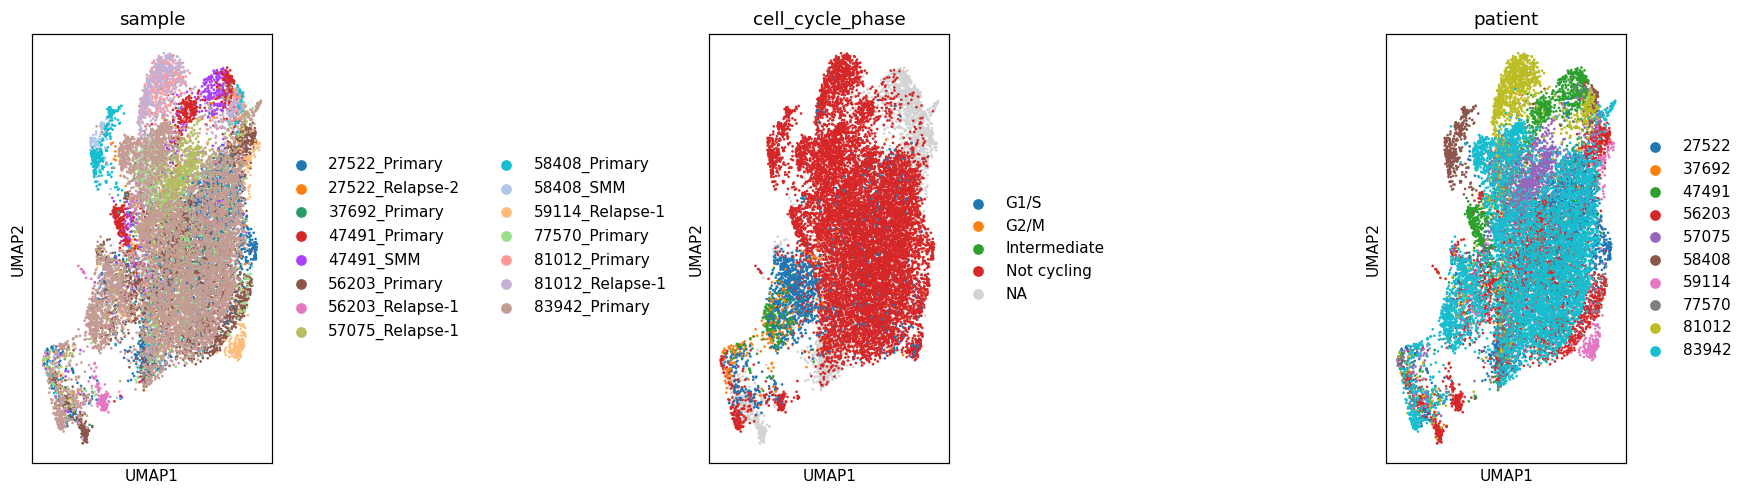

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
sc.pl.umap(adata, color='sample', size=12, ax=axes[0], show=False, title='sample', legend_loc='right margin')
sc.pl.umap(adata, color='cell_cycle_phase', size=12, ax=axes[1], show=False, title='cell_cycle_phase')
adata.obs['patient'] = adata.obs['sample'].str.split('_').str[0]
sc.pl.umap(adata, color='patient', size=12, ax=axes[2], show=False, title='patient', legend_loc='right margin')
fig.tight_layout()
n_samp = adata.obs['sample'].nunique()
print(f'{n_samp} samples share one continuous manifold; every neighbourhood mixes samples '
      f'(iLISI {sweep[theta]:.2f} of {ceiling:.2f} ceiling).')
print(f'island strip % collapses across the integration sweep: {strip_by_theta} -> clean specks at theta={theta}.')
print('Gate 1: samples intermixed on one continuous manifold (clonal MM successfully integrated) -> GO')

### Save processed data

In [9]:
adata.write(os.path.join(pth_out, 'processed.h5ad'))
print('saved processed.h5ad', adata.shape)

saved processed.h5ad (16551, 18587)


### Sample-integration figure (deliverable)
House style (`figsize=(3.5,1.5)`, `size=30`) to match every trajectory panel. Colour = sample:
intermixing across the manifold is the Gate-1 batch-integration evidence for clonal MM.

saved samples.pdf | cells: 16551


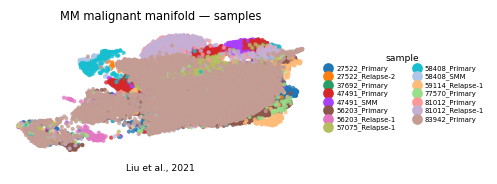

In [10]:
plot = adata.copy()
xl = plot.obsm['X_umap']
xlo, xhi = np.percentile(xl[:,0], [0.3, 99.7]); ylo, yhi = np.percentile(xl[:,1], [0.3, 99.7])
px = (xhi-xlo)*.05; py = (yhi-ylo)*.08
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='sample', size=30, alpha=.8, frameon=False, show=False, ax=ax)
h, l = ax.get_legend_handles_labels()
ax.legend(h, l, ncol=2, frameon=False, loc='center left', bbox_to_anchor=(1.02, .5),
          handletextpad=.2, labelspacing=.25, fontsize=4.5, title='sample', title_fontsize=6)
ax.set_xlim(xlo-px, xhi+px); ax.set_ylim(ylo-py, yhi+py)
ax.set_title('MM malignant manifold — samples', size=7.5)
ax.text(.5, -.12, 'Liu et al., 2021', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'samples.pdf'), bbox_inches='tight')
print('saved samples.pdf | cells:', plot.shape[0])